# Session 7 — Understanding epidemic dynamics with an SIR model

**ABM course · synthetic test data · an unidentified pathogen**

We will first build the compartmental model: how people move from susceptible to infectious to recovered, and how transmission and recovery shape the trajectory. Then we will use the synthetic test records to estimate model parameters and compare the fitted dynamics with the observations.

The goal is to understand the model and its assumptions, not to practice formal public-health epidemic classification.


## 1. A contagious setting as state transitions

In a simple SIR model, each person is in one of three compartments:

- **Susceptible (S):** can become infected.
- **Infectious (I):** currently infected and able to transmit.
- **Recovered (R):** no longer infectious and treated as immune for this model.

People move from susceptible to infectious through transmission, then from infectious to recovered. This version has no death state, births, or reinfection; the population is closed, so \(S+I+R=N\).


## 2. The mathematical representation

For a well-mixed population of size \(N\), the continuous-time SIR model is:

\[
\frac{dS}{dt}=-\beta\frac{SI}{N}, \qquad
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I, \qquad
\frac{dR}{dt}=\gamma I.
\]

The equations describe how quickly the number in each compartment changes. New infections move people from \(S\) to \(I\); recoveries move people from \(I\) to \(R\).


### What do \(\beta\), \(\gamma\), and \(R_0\) tell us?

- **\(\beta\), transmission rate:** how quickly infectious contact generates new infections in a fully susceptible, well-mixed population. Its units are per unit time.
- **\(\gamma\), recovery rate:** the rate at which infectious people recover. In this simple model, \(1/\gamma\) is the average infectious period.
- **\(R_0=\beta/\gamma\), basic reproduction number:** the average number of secondary infections generated by one infectious person when everyone is susceptible and the model assumptions hold.

At the start, when nearly everyone is susceptible, \(R_0>1\) corresponds to a growing infectious compartment and \(R_0<1\) to a shrinking one. Later, the effective reproduction number is \(R_e=R_0S/N\); as susceptibility falls, transmission can slow and infections can peak and decline.

These are model-based quantities. They describe dynamics under assumptions; they are not, by themselves, proof that a public-health authority should label an event an epidemic.


In [71]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import xlogy
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


## 3. From test records to a weekly SIR observation

Each row in the CSV is an individual test, but an SIR model needs a weekly estimate of the infectious population. We will transform the random surveillance tests into that observation. Follow-up tests are targeted, so we will use them separately to estimate recovery.

The testing design limits the routine sample to 80 tests per week after the 100-test baseline. The population size, 10,000, is used to translate sample positivity into an approximate number of infectious people.


In [72]:
TESTS_URL = "https://raw.githubusercontent.com/DACSS-Complexity/s7_epidemics/main/session7_synthetic_tests.csv"
records = pd.read_csv(TESTS_URL, parse_dates=["date"])


### Step 1: keep the representative sample

Use only `surveillance` tests for the weekly prevalence estimate. A negative surveillance test means the pathogen was not detected in that test; it does not show that the person previously had and recovered from the infection.


In [73]:
population = 10_000
surveillance = records.loc[records.test_type.eq("surveillance")].copy()
surveillance["positive"] = surveillance.result.eq("positive").astype(int)


### Step 2: count tested and positive people each week

Keep both counts. The number positive alone does not show the sample size, and the sample size matters when interpreting the estimate.


In [74]:
sir_observations = surveillance.groupby("week").agg(
    date=("date", "min"),
    tests=("test_id", "size"),
    positives=("positive", "sum"),
)


### Step 3: convert sample positivity into an infectious-share estimate

If the surveillance sample is representative and tests are perfect, its positivity estimates the share of the population that is infectious:

\[
\widehat{I/N}=\frac{\text{positive surveillance tests}}{\text{surveillance tests}}.
\]

Multiplying by the known population gives a rough estimate of the number infectious. It is a sample-based estimate, not a direct count of every infected person.


In [75]:
sir_observations["positivity"] = sir_observations.positives / sir_observations.tests
sir_observations["infectious_share_estimate"] = sir_observations.positivity
sir_observations["infectious_count_estimate"] = sir_observations.positivity * population

display(sir_observations.round(3))


,date,tests,positives,positivity,infectious_share_estimate,infectious_count_estimate
week,,,,,,
1,2026-01-05,100,0,0.000,0.000,0.0
2,2026-01-12,80,1,0.012,0.012,125.0
3,2026-01-19,80,0,0.000,0.000,0.0
4,2026-01-26,80,1,0.012,0.012,125.0
5,2026-02-02,80,4,0.050,0.050,500.0
6,2026-02-09,80,0,0.000,0.000,0.0
7,2026-02-16,80,2,0.025,0.025,250.0
8,2026-02-23,80,2,0.025,0.025,250.0
9,2026-03-02,80,8,0.100,0.100,1000.0


This is the observation table we can connect to the SIR model. It gives a weekly estimate of \(I/N\), plus the underlying positive and tested counts. We keep those counts for the statistical fit so the model accounts for the sample size rather than treating the estimated infectious count as exact.

The CSV does **not** directly give susceptible \(S\) or recovered \(R\). In particular, \(S\) is not simply population minus infectious: the SIR identity is \(S=N-I-R\). We will use the SIR transitions to track the unobserved compartments.

A weekly estimate of zero is a **sampling zero**: no positive appeared in that small sample. It does not establish that the whole population had zero infectious people. The model fit uses the positive and tested counts to account for this sampling uncertainty.


## 4. Estimate recovery from linked follow-up tests

A completed negative follow-up four weeks after a positive test is treated as recovery in this synthetic exercise. A positive follow-up means the person is still infectious at that time. We use these linked outcomes to estimate \(\gamma\).


Connect each follow-up to the person's first positive surveillance test, and keep pairs exactly four weeks apart. We use the surveillance positive as the start of one infection episode; a later positive follow-up is evidence the same episode continues, not a new infection.


In [76]:
# Use each person's first positive surveillance test as the infection reference.
prior_positive = records.loc[
    records.test_type.eq("surveillance") & records.result.eq("positive"),
    ["person_id", "week"],
].sort_values("week").drop_duplicates("person_id")
prior_positive = prior_positive.rename(columns={"week": "positive_week"})

followup_tests = records.loc[records.test_type.eq("followup")].rename(
    columns={"week": "followup_week"}
)
returned = followup_tests.merge(prior_positive, on="person_id", how="inner")
returned = returned.loc[returned.followup_week - returned.positive_week == 4].copy()
returned[["person_id", "positive_week", "followup_week", "result"]].head()


,person_id,positive_week,followup_week,result
0,P06108,2,6,positive
1,P01554,4,8,positive
2,P08942,5,9,negative
3,P04546,5,9,negative
4,P01756,5,9,negative


Under a constant recovery hazard, the probability of remaining infectious for \(d\) weeks is \(e^{-\gamma d}\). Estimate \(\gamma\) by finding the value that best matches the returned retest outcomes. Missing follow-ups are not treated as recoveries.

All follow-ups occur at the same four-week interval, so the data inform the fraction still positive at week 4. The reported average infectious period assumes exponential recovery; these observations cannot distinguish that assumption from a different distribution of recovery times.


In [77]:
from scipy.optimize import minimize_scalar
followup_interval = (returned.followup_week - returned.positive_week).to_numpy(dtype=float)
still_positive = returned.result.eq("positive").to_numpy(dtype=float)
recovered = 1 - still_positive


In [78]:
def recovery_negative_log_likelihood(gamma):
    survival = np.clip(np.exp(-gamma * followup_interval), 1e-12, 1 - 1e-12)
    return -np.sum(xlogy(still_positive, survival) + xlogy(recovered, 1 - survival))

gamma_fit = minimize_scalar(recovery_negative_log_likelihood,
                            bounds=(1e-4, 2.0), method="bounded")
GAMMA_ESTIMATE = float(gamma_fit.x)
print(f"Estimated gamma: {GAMMA_ESTIMATE:.3f} per week")


Estimated gamma: 0.113 per week


## 5. Estimate transmission from the SIR fit

Now fit \(\beta\) by comparing the SIR model's predicted infectious share with the surveillance observations. The model starts at the first post-baseline sample week; for this teaching fit, it assumes the recovered compartment is initially zero and estimates the starting infectious count.

The code advances \(S\), \(I\), and \(R\) one week at a time using the SIR transitions. This is a weekly-step approximation to the continuous differential equations introduced above.


In [79]:
observed = sir_observations.loc[sir_observations.index > 1]
observed_weeks = observed.index.to_numpy(dtype=int)
observed_n = observed.tests.to_numpy(dtype=float)
observed_positive = observed.positives.to_numpy(dtype=float)


Define one weekly transition. New infections move people from susceptible to infectious; recoveries move people from infectious to recovered.


In [80]:
def sir_one_week(susceptible, infectious, recovered_count, beta):
    new_infections = susceptible * (-np.expm1(-beta * infectious / population))
    new_recoveries = infectious * (-np.expm1(-GAMMA_ESTIMATE))
    susceptible -= new_infections
    infectious += new_infections - new_recoveries
    recovered_count += new_recoveries
    return susceptible, infectious, recovered_count


Apply that transition across the observed weeks and save the model's compartment counts.


In [81]:
def sir_states_by_week(beta, initial_infectious):
    susceptible = float(population - initial_infectious)
    infectious = float(initial_infectious)
    recovered_count = 0.0
    states = []
    previous_week = int(observed_weeks[0])

    for week in observed_weeks:
        for _ in range(int(week - previous_week)):
            susceptible, infectious, recovered_count = sir_one_week(
                susceptible, infectious, recovered_count, beta
            )
        states.append((susceptible, infectious, recovered_count))
        previous_week = int(week)

    return np.asarray(states)


The fit selects \(\beta\) and a starting infectious count that make the model's expected positive counts as consistent as possible with the observed positives out of the tested sample.


In [82]:
def surveillance_negative_log_likelihood(log_parameters):
    beta, initial_infectious = np.exp(log_parameters)
    states = sir_states_by_week(beta, initial_infectious)
    p_positive = np.clip(states[:, 1] / population, 1e-12, 1 - 1e-12)
    return -np.sum(xlogy(observed_positive, p_positive) +
                   xlogy(observed_n - observed_positive, 1 - p_positive))


In [83]:
initial_guess = max(1.0, observed_positive[:3].mean() / observed_n[:3].mean() * population)
fit = minimize(surveillance_negative_log_likelihood,
               x0=np.log([0.5, initial_guess]), method="L-BFGS-B",
               bounds=[(np.log(1e-3), np.log(2.0)),
                       (np.log(0.1), np.log(population - 1))])


In [84]:
BETA_ESTIMATE, INITIAL_INFECTIOUS_ESTIMATE = np.exp(fit.x)
R0_ESTIMATE = BETA_ESTIMATE / GAMMA_ESTIMATE
MEAN_INFECTIOUS_WEEKS_ESTIMATE = 1 / GAMMA_ESTIMATE

print(f"Estimated beta: {BETA_ESTIMATE:.3f} per week")
print(f"Estimated gamma: {GAMMA_ESTIMATE:.3f} per week")
print(f"Implied average infectious period: {MEAN_INFECTIOUS_WEEKS_ESTIMATE:.1f} weeks")
print(f"Estimated R0 = beta / gamma: {R0_ESTIMATE:.2f}")


Estimated beta: 0.444 per week
Estimated gamma: 0.113 per week
Implied average infectious period: 8.8 weeks
Estimated R0 = beta / gamma: 3.91


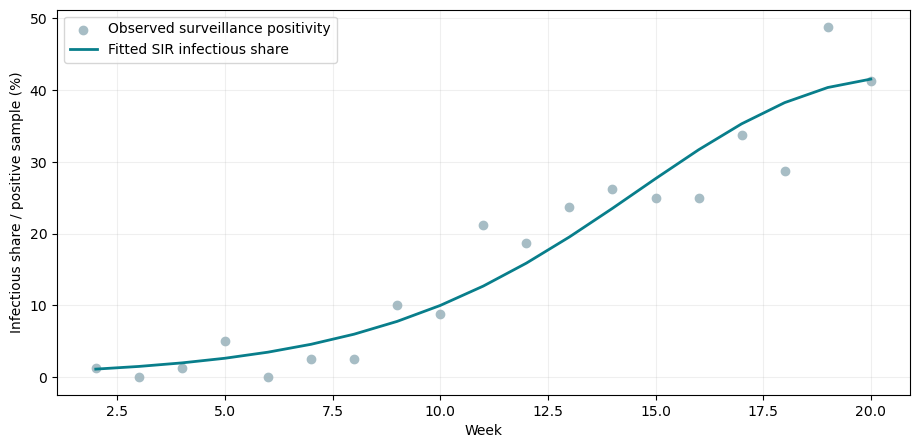

In [85]:
fitted_states = sir_states_by_week(BETA_ESTIMATE, INITIAL_INFECTIOUS_ESTIMATE)
plt.figure(figsize=(11, 5))
plt.scatter(observed_weeks, 100 * observed_positive / observed_n,
            color="#a7bdc5", label="Observed surveillance positivity")
plt.plot(observed_weeks, 100 * fitted_states[:, 1] / population,
         color="#087e8b", linewidth=2, label="Fitted SIR infectious share")
plt.xlabel("Week")
plt.ylabel("Infectious share / positive sample (%)")
plt.legend()
plt.grid(alpha=.2)
plt.show()


### Interpret the fitted parameters

\(\beta\) and \(\gamma\) represent different flows in the model; \(R_0=\beta/\gamma\) summarizes initial transmission potential when everyone is susceptible. The fitted curve illustrates how these transition rates combine to produce the estimated infectious trajectory.

These are model-based estimates from a small synthetic sample. The basic reproduction number is not a count of exactly how many people each infected person will infect.


## 6. Continue the fitted SIR trajectory

The CSV ends during the rising phase. Continue the fitted model forward to examine when its effective reproduction number, \(R_e=R_0S/N\), falls below 1 and when infectious prevalence peaks. This is a conditional model projection, not an observed downturn.


In [86]:
S_proj, I_proj, R_proj = fitted_states[-1].astype(float)
last_week = int(observed_weeks[-1])
last_date = sir_observations.loc[last_week, "date"]
projection_rows = []
week = last_week
initial_Re = R0_ESTIMATE * S_proj / population
crossing_date = last_date if initial_Re < 1 else None
previous_I = I_proj


In [87]:
# For this fitted SIR trajectory, follow the curve through the Re crossing and its first decline.
for _ in range(520):  # stop after at most ten projected years
    week += 1
    S_proj, I_proj, R_proj = sir_one_week(S_proj, I_proj, R_proj, BETA_ESTIMATE)
    date = last_date + pd.Timedelta(weeks=week-last_week)
    Re_now = R0_ESTIMATE * S_proj / population
    projection_rows.append((week, date, S_proj, I_proj, R_proj, Re_now))

    if crossing_date is None and Re_now < 1:
        crossing_date = date
    if I_proj <= 0 or (crossing_date is not None and I_proj <= previous_I + 1e-12):
        break
    previous_I = I_proj


In [88]:
projection = pd.DataFrame(projection_rows,
    columns=["week", "date", "susceptible", "infectious", "recovered", "Re"])
HERD_THRESHOLD_ESTIMATE = 1 - 1 / R0_ESTIMATE if R0_ESTIMATE > 1 else 0.0
print(f"Estimated immune-share threshold in this model: {100*HERD_THRESHOLD_ESTIMATE:.1f}%")


Estimated immune-share threshold in this model: 74.5%


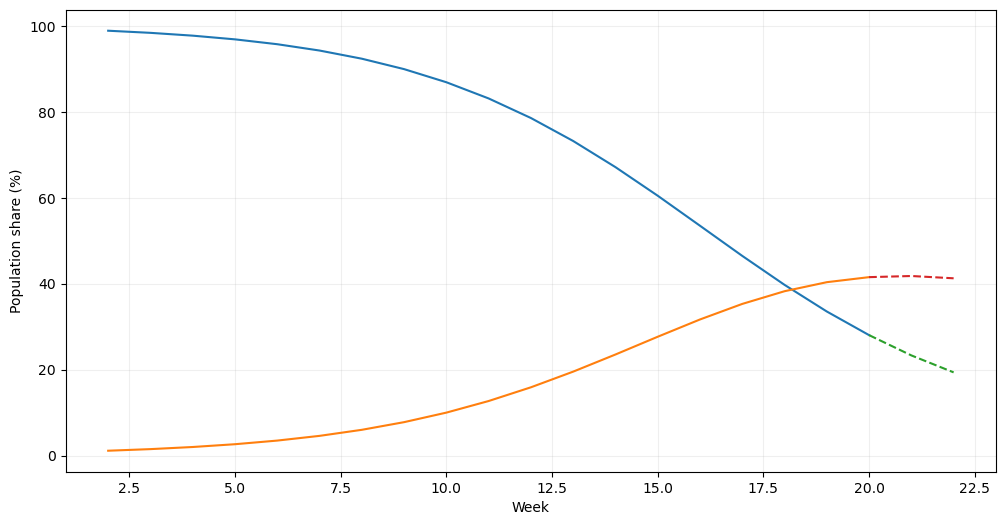

In [89]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(observed_weeks, 100*fitted_states[:, 0]/population, label="Fitted susceptible (%)")
ax.plot(observed_weeks, 100*fitted_states[:, 1]/population, label="Fitted infectious (%)")

# Include the final fitted point so each dashed curve continues from the observed fit.
if len(projection):
    projected_line = pd.concat([
        pd.DataFrame({"week": [last_week], "susceptible": [fitted_states[-1, 0]],
                      "infectious": [fitted_states[-1, 1]]}),
        projection[["week", "susceptible", "infectious"]],
    ], ignore_index=True)
    ax.plot(projected_line.week, 100*projected_line.susceptible/population, "--",
            label="Projected susceptible (%)")
    ax.plot(projected_line.week, 100*projected_line.infectious/population, "--",
            label="Projected infectious (%)")

ax.set_xlabel("Week")
ax.set_ylabel("Population share (%)")
ax.grid(alpha=.2)


In [90]:
ax2 = ax.twinx()
observed_Re = R0_ESTIMATE * fitted_states[:, 0] / population
ax2.plot(observed_weeks, observed_Re, color="#7952a3", linestyle=":", label=r"Fitted $R_e$")
if len(projection):
    ax2.plot(projection.week, projection.Re, color="#7952a3", linestyle="--",
             label=r"Projected $R_e$")
ax2.axhline(1, color="#7952a3", alpha=.5, linewidth=1)
ax2.set_ylabel(r"Effective reproduction number $R_e$")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, labels1+labels2, loc="upper right")
plt.show()


In [91]:
all_weeks = np.concatenate([observed_weeks, projection.week.to_numpy(dtype=int)])
all_infectious = np.concatenate([fitted_states[:, 1], projection.infectious.to_numpy()])
peak_week = int(all_weeks[np.argmax(all_infectious)])
if peak_week in sir_observations.index:
    peak_date = sir_observations.loc[peak_week, "date"]
else:
    peak_date = projection.loc[projection.week.eq(peak_week), "date"].iloc[0]

if initial_Re < 1:
    print(f"Re was already below 1 at the final fitted week ({last_date.date()}).")
elif crossing_date is not None:
    print(f"In this fitted scenario, Re first falls below 1 around {crossing_date.date()}.")
else:
    print("Re did not fall below 1 during the ten-year projection.")
print(f"The infectious count peaks around {peak_date.date()}.")


In this fitted scenario, Re first falls below 1 around 2026-05-25.
The infectious count peaks around 2026-05-25.


### Assumptions and limits

This exercise assumes a closed population, homogeneous mixing, lasting immunity, perfect tests, a constant recovery hazard, and representative random surveillance. It also simplifies the starting state by setting \(R=0\) at the first fitted week. The CSV has completed tests only; missing follow-ups do not show whether a person was not selected or did not return. These assumptions affect the fitted parameters and projected trajectory.

The purpose is to connect individual test records to compartmental dynamics, not to classify a real-world epidemic.


## Student exercises

1. Explain how the weekly surveillance records become an estimate of \(I/N\). Why is this an estimate rather than a census?
2. Why can we not calculate \(S=N-I\) from the test data once the recovered compartment exists?
3. Explain how the linked follow-up results inform \(\gamma\), and how the SIR fit uses surveillance positives to estimate \(\beta\).
4. If \(\beta\) rises while \(\gamma\) stays fixed, how should the infectious trajectory and \(R_0\) change?
5. Why does the projected decline depend on recovered people remaining immune?
